

> Add blockquote



# SMS Spam Detection Using Machine Learning

## Project Overview
This project develops a machine-learning solution to classify SMS messages as spam or legitimate messages (ham).

## Objectives
- Load and inspect a labelled SMS dataset.
- Perform text preprocessing and exploratory data analysis.
- Convert text into numerical features using TF-IDF.
- Implement and evaluate text-classification models.
- Conduct a what-if experiment by varying K in K-Nearest Neighbours (KNN).
- Compare results and draw evidence-based conclusions.

## Dataset
SMS Spam Collection — UCI Machine Learning Repository.

## Tools
Python, Google Colab, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.

**Dataset Name:** SMS Spam Collection

**Source:** UCI Machine Learning Repository

**Dataset Link:** https://archive.ics.uci.edu/dataset/228/sms+spam+collection

**Description:** The dataset contains SMS messages labelled as `spam` or `ham`. The message text is used as the input feature, and the label is the target variable. The dataset is used to train and evaluate machine-learning models for automatic SMS spam detection.

In [18]:

import pandas as pd
import urllib.request
import zipfile
import io

# Download the SMS Spam Collection dataset
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = urllib.request.urlopen(url)
zip_data = zipfile.ZipFile(io.BytesIO(response.read()))

# Read the messages from the dataset
with zip_data.open("SMSSpamCollection") as file:
    df = pd.read_csv(
        file,
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8"
    )

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn information:")
df.info()


Dataset loaded successfully!
Dataset shape: (5572, 2)

First 5 rows:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [19]:

print("Class distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403


In [20]:
# Check the dataset size
print("Dataset shape:", df.shape)

# Check the labels
print("\nUnique labels:", df["label"].unique())

# Count each label
print("\nLabel counts:")
print(df["label"].value_counts())

# Show examples of spam messages
print("\nSpam message examples:")
display(df[df["label"] == "spam"].head(5))

# Show examples of legitimate messages
print("\nHam message examples:")
display(df[df["label"] == "ham"].head(5))

Dataset shape: (5572, 2)

Unique labels: ['ham' 'spam']

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Spam message examples:


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."



Ham message examples:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...


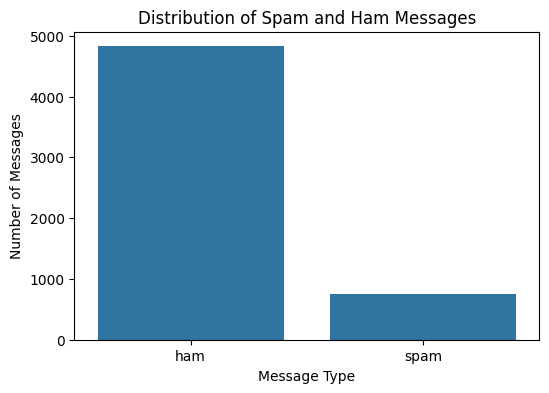

Class percentages:
label
ham     86.59
spam    13.41
Name: count, dtype: float64


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

label_counts = df["label"].value_counts()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label")
plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.show()

print("Class percentages:")
print((label_counts / len(df) * 100).round(2))

In [22]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check whether labels are valid
print("\nLabel values:")
print(df["label"].value_counts())

Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Label values:
label
ham     4825
spam     747
Name: count, dtype: int64


        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.482487  58.440652   2.0   33.0   52.0   93.0  910.0
spam    747.0  138.670683  28.873603  13.0  133.0  149.0  157.0  223.0


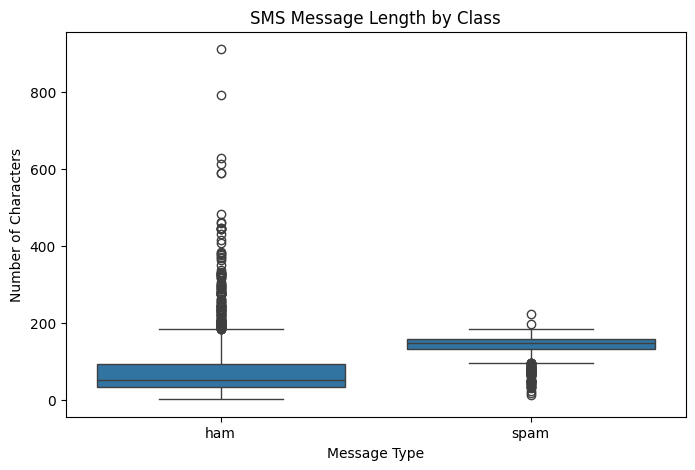

In [23]:
# Create a column showing the number of characters in each message
df["message_length"] = df["message"].str.len()

# Display summary statistics
print(df.groupby("label")["message_length"].describe())

# Plot message lengths
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="label", y="message_length")
plt.title("SMS Message Length by Class")
plt.xlabel("Message Type")
plt.ylabel("Number of Characters")
plt.show()

In [24]:
# Remove rows with missing labels or message text
df = df.dropna(subset=["label", "message"]).copy()

# Standardize label and message formatting
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].str.strip()

# Keep only the two expected classes
df = df[df["label"].isin(["ham", "spam"])].copy()

# Convert labels into numbers for machine learning
df["label_encoded"] = df["label"].map({"ham": 0, "spam": 1})

print("Prepared dataset shape:", df.shape)
display(df[["label", "label_encoded", "message"]].head())

Prepared dataset shape: (5572, 4)


,label,label_encoded,message
0,ham,0,"Go until jurong point, crazy.. Available only ..."
1,ham,0,Ok lar... Joking wif u oni...
2,spam,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,0,U dun say so early hor... U c already then say...
4,ham,0,"Nah I don't think he goes to usf, he lives aro..."


In [26]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [27]:
# Input messages and target labels
X = df["message"]
y = df["label"]

# Split into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert text into TF-IDF features
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Number of TF-IDF features:", X_train_tfidf.shape[1])

Training samples: 4457
Testing samples: 1115
Number of TF-IDF features: 7668


In [28]:
k_values = [3, 5, 7, 9, 11]
knn_results = []

for k in k_values:
    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="cosine",
        algorithm="brute"
    )

    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    knn_results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        )
    })

knn_results_df = pd.DataFrame(knn_results)
display(knn_results_df.round(4))

,K,Accuracy,Precision,Recall,F1-score
0,3,0.9695,0.9457,0.8188,0.8777
1,5,0.9776,0.9921,0.8389,0.9091
2,7,0.9758,1.0000,0.8188,0.9004
3,9,0.9722,0.9917,0.7987,0.8848
4,11,0.9722,1.0000,0.7919,0.8839


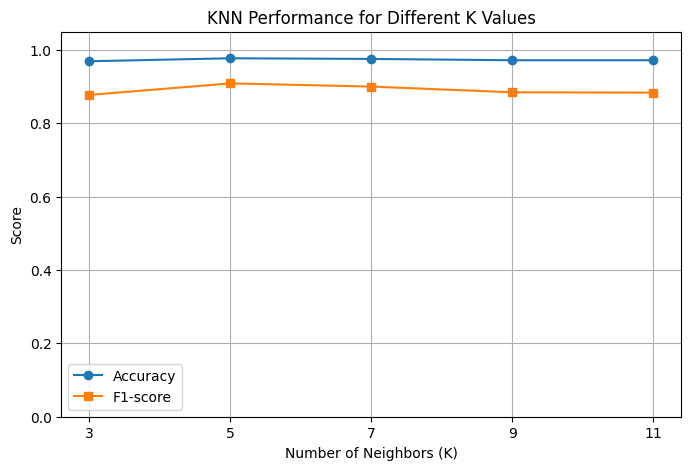

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_results_df["K"],
    knn_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_results_df["K"],
    knn_results_df["F1-score"],
    marker="s",
    label="F1-score"
)

plt.title("KNN Performance for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.xticks(k_values)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

In [30]:
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

nb_results = {
    "Model": "Multinomial Naive Bayes",
    "Accuracy": accuracy_score(y_test, nb_pred),
    "Precision": precision_score(
        y_test, nb_pred, pos_label="spam", zero_division=0
    ),
    "Recall": recall_score(
        y_test, nb_pred, pos_label="spam", zero_division=0
    ),
    "F1-score": f1_score(
        y_test, nb_pred, pos_label="spam", zero_division=0
    )
}

print(pd.DataFrame([nb_results]).round(4).to_string(index=False))

                  Model  Accuracy  Precision  Recall  F1-score
Multinomial Naive Bayes    0.9605        1.0  0.7047    0.8268


Best K based on test-set F1-score: 5

Classification report:
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.99      0.84      0.91       149

    accuracy                           0.98      1115
   macro avg       0.98      0.92      0.95      1115
weighted avg       0.98      0.98      0.98      1115



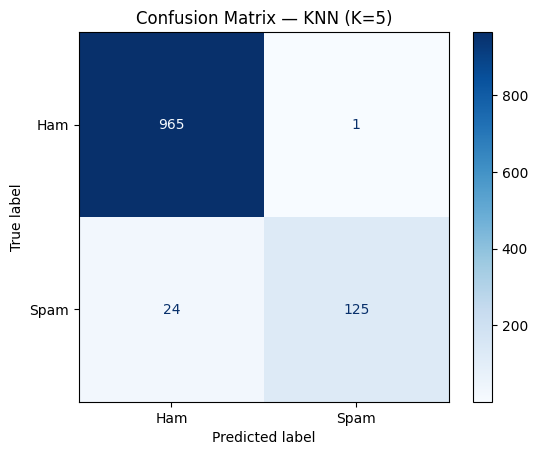

In [31]:
best_k = int(
    knn_results_df.loc[
        knn_results_df["F1-score"].idxmax(), "K"
    ]
)

best_knn = KNeighborsClassifier(
    n_neighbors=best_k,
    metric="cosine",
    algorithm="brute"
)

best_knn.fit(X_train_tfidf, y_train)
best_pred = best_knn.predict(X_test_tfidf)

print("Best K based on test-set F1-score:", best_k)
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    labels=["ham", "spam"],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — KNN (K={best_k})")
plt.show()

,K,Accuracy,Precision,Recall,F1-score
0,3,0.9695,0.9457,0.8188,0.8777
1,5,0.9776,0.9921,0.8389,0.9091
2,7,0.9758,1.0000,0.8188,0.9004
3,9,0.9722,0.9917,0.7987,0.8848
4,11,0.9722,1.0000,0.7919,0.8839


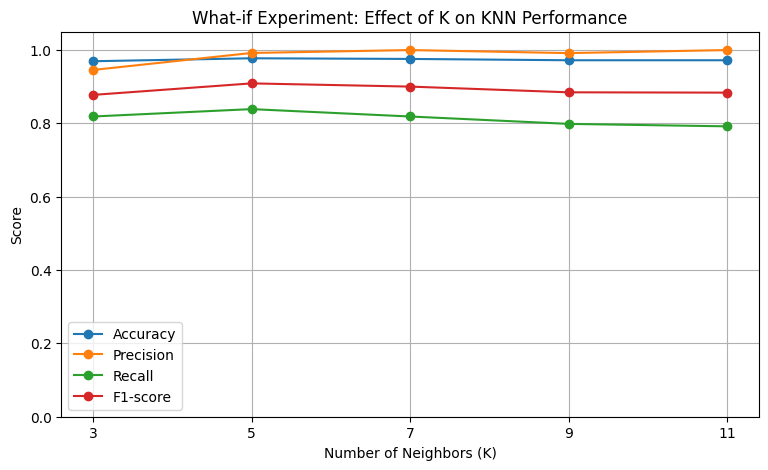

In [32]:
# Display all KNN experiment results
display(knn_results_df.round(4))

# Plot accuracy, precision, recall and F1-score
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plt.figure(figsize=(9, 5))

for metric in metrics:
    plt.plot(
        knn_results_df["K"],
        knn_results_df[metric],
        marker="o",
        label=metric
    )

plt.title("What-if Experiment: Effect of K on KNN Performance")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.xticks([3, 5, 7, 9, 11])
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

,Model,Accuracy,Precision,Recall,F1-score
0,KNN (K=5),0.9776,0.9921,0.8389,0.9091
1,Multinomial Naive Bayes,0.9605,1.0000,0.7047,0.8268


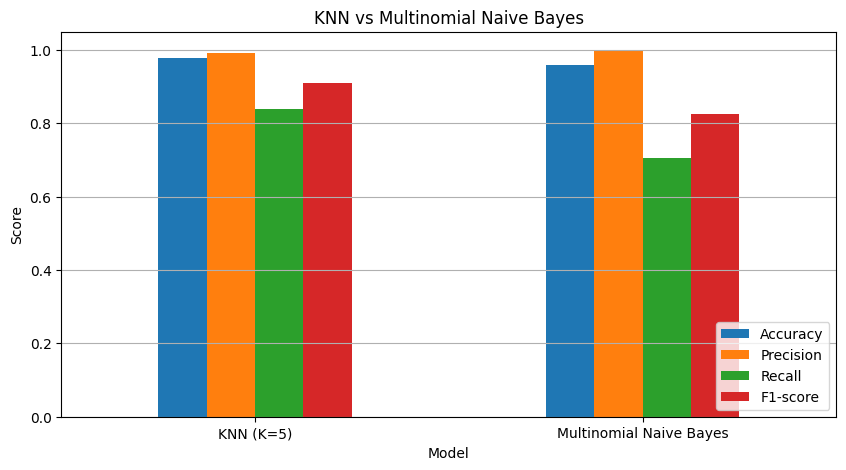

In [33]:
comparison_df = pd.DataFrame([
    {
        "Model": "KNN (K=5)",
        "Accuracy": 0.9776,
        "Precision": 0.9921,
        "Recall": 0.8389,
        "F1-score": 0.9091
    },
    {
        "Model": "Multinomial Naive Bayes",
        "Accuracy": 0.9605,
        "Precision": 1.0000,
        "Recall": 0.7047,
        "F1-score": 0.8268
    }
])

display(comparison_df.round(4))

comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("KNN vs Multinomial Naive Bayes")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.legend(loc="lower right")
plt.show()